In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA, FactorAnalysis
from sklearn.pipeline import Pipeline

from sklearn.metrics import mean_squared_error, mean_absolute_error

import os
import warnings
warnings.filterwarnings("ignore")

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:

import pandas as pd

# Load datasets directly from the Colab files directory
train = pd.read_csv("/content/train_final.csv")
validation = pd.read_csv("/content/validation_final.csv")
test = pd.read_csv("/content/test_final.csv")

# Display dataset dimensions
print("Training:", train.shape)
print("Validation:", validation.shape)
print("Testing:", test.shape)

# Display first five rows
display(train.head())

Training: (19349, 43)
Validation: (4141, 43)
Testing: (4142, 43)


,period,hour,bx_gse_mean,bx_gse_std,by_gse_mean,by_gse_std,bz_gse_mean,bz_gse_std,theta_gse_mean,theta_gse_std,...,bt,dynamic_pressure,delta_bz,delta_speed,delta_density,delta_bt,bz_south_3h_mean,bz_south_6h_mean,speed_3h_mean,density_3h_mean
0,train_a,0 days 06:00:00,-4.126364,1.367697,-4.238545,0.675515,0.857091,1.080214,7.516545,10.110191,...,6.635455,1.586910,0.118758,2.088375,-0.132672,0.269955,0.0,0.0,371.475058,3.917961
1,train_a,0 days 07:00:00,-1.965800,1.515395,-5.021800,0.807396,0.209200,1.355265,1.290800,12.566633,...,6.193200,1.657809,-0.647891,14.993830,-0.177708,-0.442255,0.0,0.0,388.337016,4.992391
2,train_a,0 days 08:00:00,-3.017667,1.031393,-4.386833,0.514240,0.636667,0.671411,6.137167,6.816736,...,5.885000,2.140559,0.427467,-7.346371,1.962314,-0.308200,0.0,0.0,402.702780,5.962488
3,train_a,0 days 09:00:00,-3.748333,0.857144,-3.406333,0.916484,1.138500,0.536908,11.600500,5.173960,...,5.728667,2.299433,0.501833,-9.673593,0.988067,-0.156333,0.0,0.0,405.948058,6.513132
4,train_a,0 days 10:00:00,-4.614833,0.320262,-2.613167,0.799200,2.127333,0.525608,20.269667,4.876620,...,6.148500,2.181783,0.988833,-5.527108,-0.211225,0.419833,0.0,0.0,405.272680,7.437356


In [ ]:

print("TRAINING DATASET")
print("Shape:", train.shape)
print("Columns:")
print(train.columns.tolist())

print("\nMISSING VALUES:")
print(train.isnull().sum().sum())

print("\nDATA TYPES:")
print(train.dtypes)

print("\nFEATURE COLUMNS FILE:")
feature_data = pd.read_csv("/content/feature_columns.csv")
display(feature_data.head(10))


TRAINING DATASET
Shape: (19349, 43)
Columns:
['period', 'hour', 'bx_gse_mean', 'bx_gse_std', 'by_gse_mean', 'by_gse_std', 'bz_gse_mean', 'bz_gse_std', 'theta_gse_mean', 'theta_gse_std', 'phi_gse_mean', 'phi_gse_std', 'bx_gsm_mean', 'bx_gsm_std', 'by_gsm_mean', 'by_gsm_std', 'bz_gsm_mean', 'bz_gsm_std', 'theta_gsm_mean', 'theta_gsm_std', 'phi_gsm_mean', 'phi_gsm_std', 'bt_mean', 'bt_std', 'density_mean', 'density_std', 'speed_mean', 'speed_std', 'temperature_mean', 'temperature_std', 'timedelta', 'dst', 'bz_south', 'bt', 'dynamic_pressure', 'delta_bz', 'delta_speed', 'delta_density', 'delta_bt', 'bz_south_3h_mean', 'bz_south_6h_mean', 'speed_3h_mean', 'density_3h_mean']

MISSING VALUES:
0

DATA TYPES:
period               object
hour                 object
bx_gse_mean         float64
bx_gse_std          float64
by_gse_mean         float64
by_gse_std          float64
bz_gse_mean         float64
bz_gse_std          float64
theta_gse_mean      float64
theta_gse_std       float64
phi_gse_me

,feature
0,bx_gse_mean
1,bx_gse_std
2,by_gse_mean
3,by_gse_std
4,bz_gse_mean
5,bz_gse_std
6,theta_gse_mean
7,theta_gse_std
8,phi_gse_mean
9,phi_gse_std


In [ ]:

# Extract feature names from the existing feature list
feature_candidates = feature_data.values.flatten().tolist()

# Keep only names that actually exist in the training dataset
feature_columns = [
    col for col in feature_candidates
    if isinstance(col, str) and col in train.columns
]

# Remove duplicates
feature_columns = list(dict.fromkeys(feature_columns))

print("Number of selected features:", len(feature_columns))
print("\nSelected features:")
print(feature_columns)


Number of selected features: 39

Selected features:
['bx_gse_mean', 'bx_gse_std', 'by_gse_mean', 'by_gse_std', 'bz_gse_mean', 'bz_gse_std', 'theta_gse_mean', 'theta_gse_std', 'phi_gse_mean', 'phi_gse_std', 'bx_gsm_mean', 'bx_gsm_std', 'by_gsm_mean', 'by_gsm_std', 'bz_gsm_mean', 'bz_gsm_std', 'theta_gsm_mean', 'theta_gsm_std', 'phi_gsm_mean', 'phi_gsm_std', 'bt_mean', 'bt_std', 'density_mean', 'density_std', 'speed_mean', 'speed_std', 'temperature_mean', 'temperature_std', 'bz_south', 'bt', 'dynamic_pressure', 'delta_bz', 'delta_speed', 'delta_density', 'delta_bt', 'bz_south_3h_mean', 'bz_south_6h_mean', 'speed_3h_mean', 'density_3h_mean']


In [ ]:

# Select features from all three datasets
X_train = train[feature_columns].copy()
X_val = validation[feature_columns].copy()
X_test = test[feature_columns].copy()

# Handle missing values using training medians
imputer = SimpleImputer(strategy="median")

X_train_imputed = imputer.fit_transform(X_train)
X_val_imputed = imputer.transform(X_val)
X_test_imputed = imputer.transform(X_test)

# Standardize features
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_imputed)
X_val_scaled = scaler.transform(X_val_imputed)
X_test_scaled = scaler.transform(X_test_imputed)

print("Preprocessing completed!")
print("Training:", X_train_scaled.shape)
print("Validation:", X_val_scaled.shape)
print("Testing:", X_test_scaled.shape)


Preprocessing completed!
Training: (19349, 39)
Validation: (4141, 39)
Testing: (4142, 39)


In [ ]:

# Apply PCA on training data
pca = PCA()

X_train_pca = pca.fit_transform(X_train_scaled)

# Transform validation and testing data
X_val_pca = pca.transform(X_val_scaled)
X_test_pca = pca.transform(X_test_scaled)

print("Original number of features:", X_train_scaled.shape[1])
print("Number of principal components:", X_train_pca.shape[1])



Original number of features: 39
Number of principal components: 39


In [ ]:

explained_variance = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

pca_results = pd.DataFrame({
    "Principal Component": [
        f"PC{i+1}" for i in range(len(explained_variance))
    ],
    "Explained Variance": explained_variance,
    "Cumulative Variance": cumulative_variance
})

display(pca_results.round(4))


,Principal Component,Explained Variance,Cumulative Variance
0,PC1,0.2126,0.2126
1,PC2,0.1498,0.3624
2,PC3,0.1028,0.4652
3,PC4,0.0988,0.5640
4,PC5,0.0671,0.6311
5,PC6,0.0477,0.6788
6,PC7,0.0388,0.7175
7,PC8,0.0369,0.7544
8,PC9,0.0297,0.7841
9,PC10,0.0259,0.8101


In [ ]:
os.makedirs("/content/results/pratistha", exist_ok=True)

pca_results.to_csv(
    "/content/results/pratistha/pca_explained_variance.csv",
    index=False
)

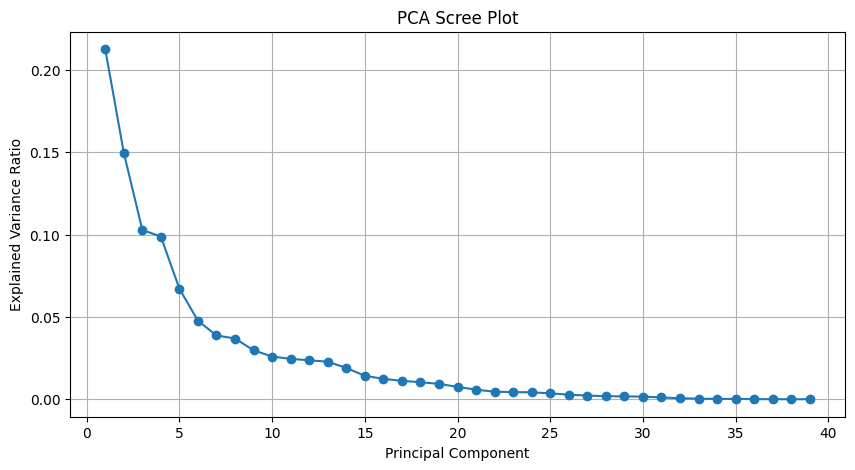

In [ ]:

plt.figure(figsize=(10, 5))

plt.plot(
    range(1, len(explained_variance) + 1),
    explained_variance,
    marker="o"
)

plt.xlabel("Principal Component")
plt.ylabel("Explained Variance Ratio")
plt.title("PCA Scree Plot")
plt.grid(True)

plt.savefig(
    "/content/results/pratistha/pca_scree_plot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


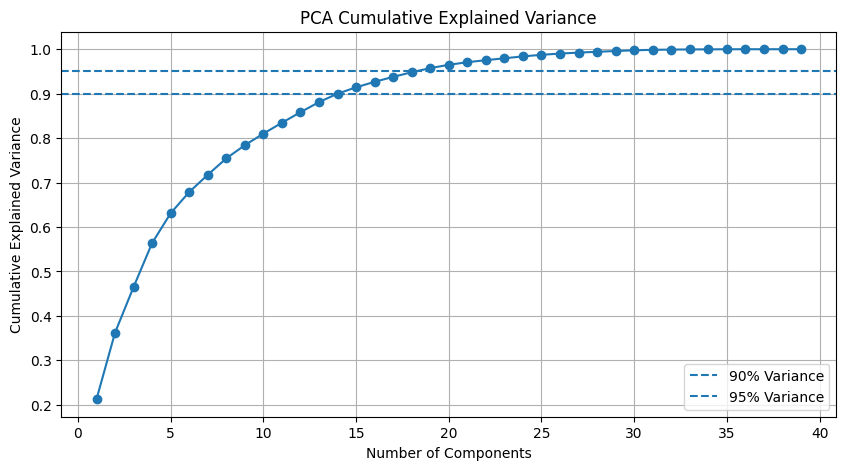

In [ ]:

plt.figure(figsize=(10, 5))

plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker="o"
)

plt.axhline(y=0.90, linestyle="--", label="90% Variance")
plt.axhline(y=0.95, linestyle="--", label="95% Variance")

plt.xlabel("Number of Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA Cumulative Explained Variance")

plt.legend()
plt.grid(True)

plt.savefig(
    "/content/results/pratistha/pca_cumulative_variance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [ ]:

components_90 = np.argmax(cumulative_variance >= 0.90) + 1
components_95 = np.argmax(cumulative_variance >= 0.95) + 1

print("Components needed for 90% variance:", components_90)
print("Components needed for 95% variance:", components_95)


Components needed for 90% variance: 14
Components needed for 95% variance: 19


In [ ]:
print(train.columns.tolist())

['period', 'hour', 'bx_gse_mean', 'bx_gse_std', 'by_gse_mean', 'by_gse_std', 'bz_gse_mean', 'bz_gse_std', 'theta_gse_mean', 'theta_gse_std', 'phi_gse_mean', 'phi_gse_std', 'bx_gsm_mean', 'bx_gsm_std', 'by_gsm_mean', 'by_gsm_std', 'bz_gsm_mean', 'bz_gsm_std', 'theta_gsm_mean', 'theta_gsm_std', 'phi_gsm_mean', 'phi_gsm_std', 'bt_mean', 'bt_std', 'density_mean', 'density_std', 'speed_mean', 'speed_std', 'temperature_mean', 'temperature_std', 'timedelta', 'dst', 'bz_south', 'bt', 'dynamic_pressure', 'delta_bz', 'delta_speed', 'delta_density', 'delta_bt', 'bz_south_3h_mean', 'bz_south_6h_mean', 'speed_3h_mean', 'density_3h_mean']


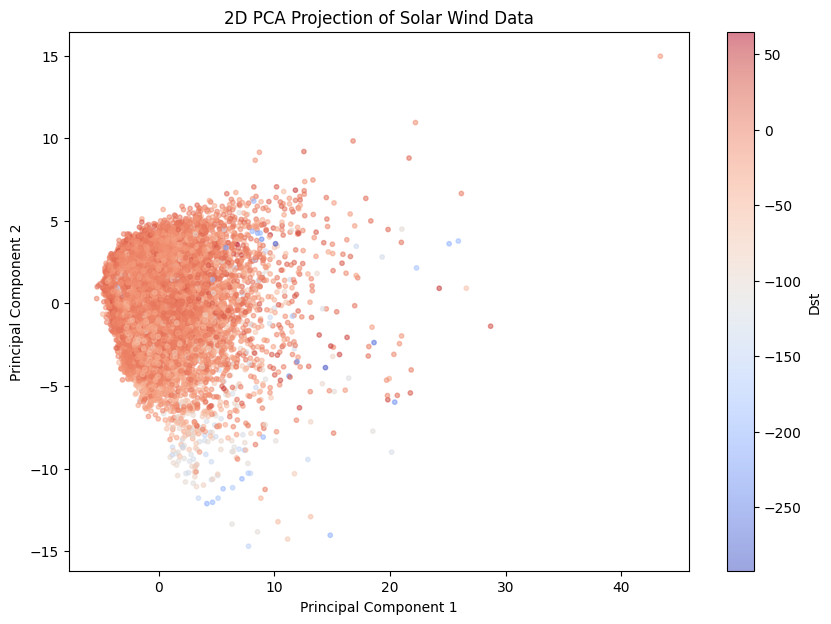

In [ ]:

# Fit a separate 2-component PCA for visualization
pca_2d = PCA(n_components=2)
X_train_2d = pca_2d.fit_transform(X_train_scaled)

plt.figure(figsize=(10, 7))

scatter = plt.scatter(
    X_train_2d[:, 0],
    X_train_2d[:, 1],
    c=train["dst"],
    cmap="coolwarm",
    alpha=0.5,
    s=10
)

plt.colorbar(scatter, label="Dst")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("2D PCA Projection of Solar Wind Data")

plt.savefig(
    "/content/results/pratistha/pca_2d_projection.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [ ]:

factor_results = []

best_fa = None
best_score = -np.inf
best_n_factors = None

for n in range(2, min(9, X_train_scaled.shape[1])):

    fa_model = FactorAnalysis(
        n_components=n,
        random_state=42,
        max_iter=1000
    )

    fa_model.fit(X_train_scaled)

    validation_score = fa_model.score(X_val_scaled)

    factor_results.append({
        "Number of Factors": n,
        "Validation Log Likelihood": validation_score
    })

    if validation_score > best_score:
        best_score = validation_score
        best_fa = fa_model
        best_n_factors = n

factor_comparison = pd.DataFrame(factor_results)

display(factor_comparison.round(4))

print("Selected number of factors:", best_n_factors)


,Number of Factors,Validation Log Likelihood
0,2,-62.9858
1,3,-61.3344
2,4,-62.1488
3,5,-46.1959
4,6,-44.7787
5,7,-43.9135
6,8,-42.6929


Selected number of factors: 8


In [ ]:

fa = best_fa

loadings = pd.DataFrame(
    fa.components_.T,
    index=feature_columns,
    columns=[
        f"Factor {i+1}" for i in range(best_n_factors)
    ]
)

display(loadings.round(4))

loadings.to_csv(
    "/content/results/pratistha/factor_loadings.csv"
)


,Factor 1,Factor 2,Factor 3,Factor 4,Factor 5,Factor 6,Factor 7,Factor 8
bx_gse_mean,-0.3154,-0.0750,-0.1244,0.3648,-0.1918,-0.0064,0.1194,0.3762
bx_gse_std,0.3592,0.1938,-0.1188,0.3971,0.3283,-0.0934,0.0034,0.1492
by_gse_mean,0.1762,0.0912,0.2415,-0.6586,0.6548,0.0387,0.0399,0.0282
by_gse_std,0.4191,0.1912,-0.1139,0.4246,0.3113,-0.0760,0.0468,0.3079
bz_gse_mean,-0.0433,-0.1017,-0.7872,-0.1138,-0.0222,0.1245,0.4928,-0.0424
bz_gse_std,0.4487,0.2150,-0.1906,0.5289,0.5313,-0.3173,0.0192,-0.0996
theta_gse_mean,-0.0268,-0.0968,-0.7187,-0.0970,-0.0344,0.1175,0.5112,-0.0088
theta_gse_std,-0.1038,0.2629,-0.1574,0.5618,0.5364,-0.3207,0.0533,-0.0051
phi_gse_mean,-0.0952,-0.0977,-0.2173,0.5191,-0.5299,-0.0684,-0.0135,-0.0369
phi_gse_std,-0.1813,0.1308,-0.1070,0.3013,0.1518,-0.0002,0.1474,0.7912


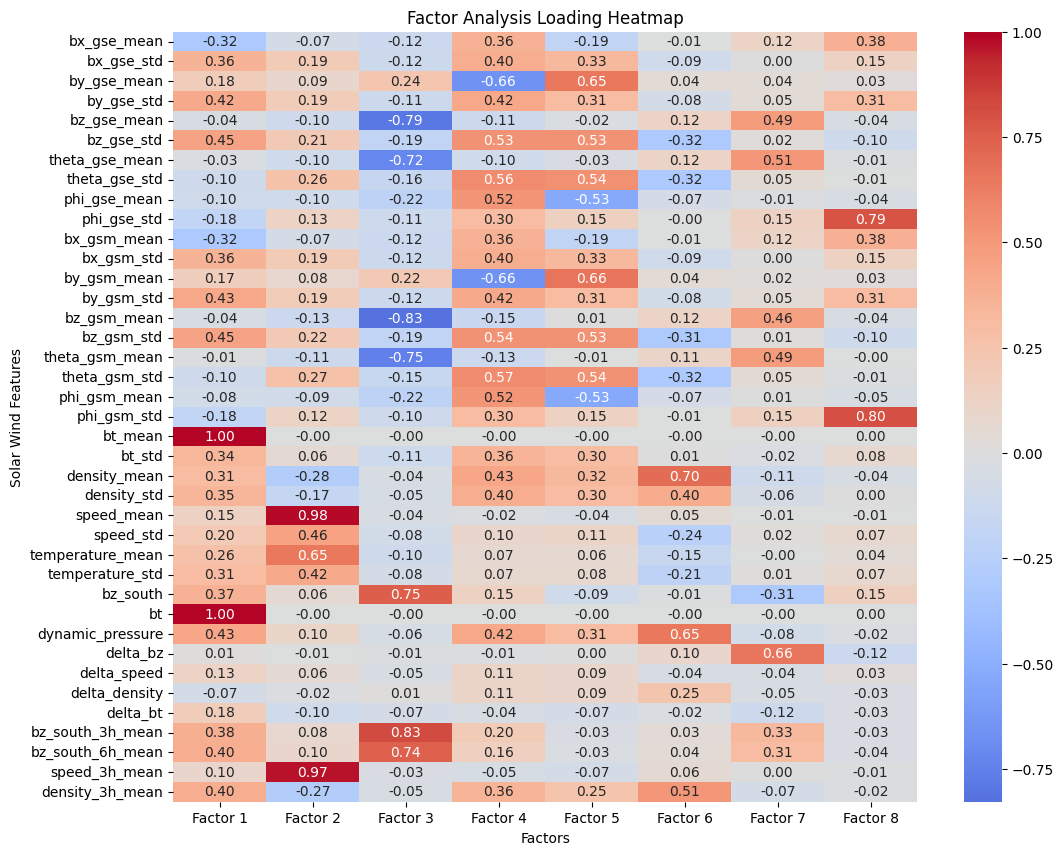

In [ ]:

plt.figure(figsize=(12, 10))

sns.heatmap(
    loadings,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f"
)

plt.title("Factor Analysis Loading Heatmap")
plt.xlabel("Factors")
plt.ylabel("Solar Wind Features")

plt.savefig(
    "/content/results/pratistha/factor_loading_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [ ]:
%pip install statsmodels

In [ ]:
print([c for c in train.columns if "dst" in c.lower()])

['dst']


In [ ]:

from statsmodels.tsa.statespace.structural import UnobservedComponents

# Use training Dst observations only
dst_series = train["dst"].astype(float).reset_index(drop=True)

# Remove missing observations for this demonstration
dst_series = dst_series.dropna()

print("Number of Dst observations:", len(dst_series))
display(dst_series.head())


Number of Dst observations: 19349


,dst
0,5.0
1,5.0
2,3.0
3,1.0
4,1.0


In [ ]:

# Create local-level state-space model
model = UnobservedComponents(
    dst_series,
    level="local level"
)

# Estimate model parameters and filter the series
kalman_result = model.fit(disp=False)

# Extract filtered state and uncertainty
filtered_dst = kalman_result.filtered_state[0]

filtered_variance = kalman_result.filtered_state_cov[0, 0, :]

print(kalman_result.summary())


                        Unobserved Components Results                         
Dep. Variable:                    dst   No. Observations:                19349
Model:                    local level   Log Likelihood              -59754.453
Date:                Wed, 04 Nov 2026   AIC                         119512.907
Time:                        16:58:04   BIC                         119528.647
Sample:                             0   HQIC                        119518.065
                              - 19349                                         
Covariance Type:                  opg                                         
                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
sigma2.irregular  1.662e-10      0.067   2.47e-09      1.000      -0.132       0.132
sigma2.level        28.1888      0.115    245.058      0.000      27.963      28.414
Ljung-Box (L1) (Q):         

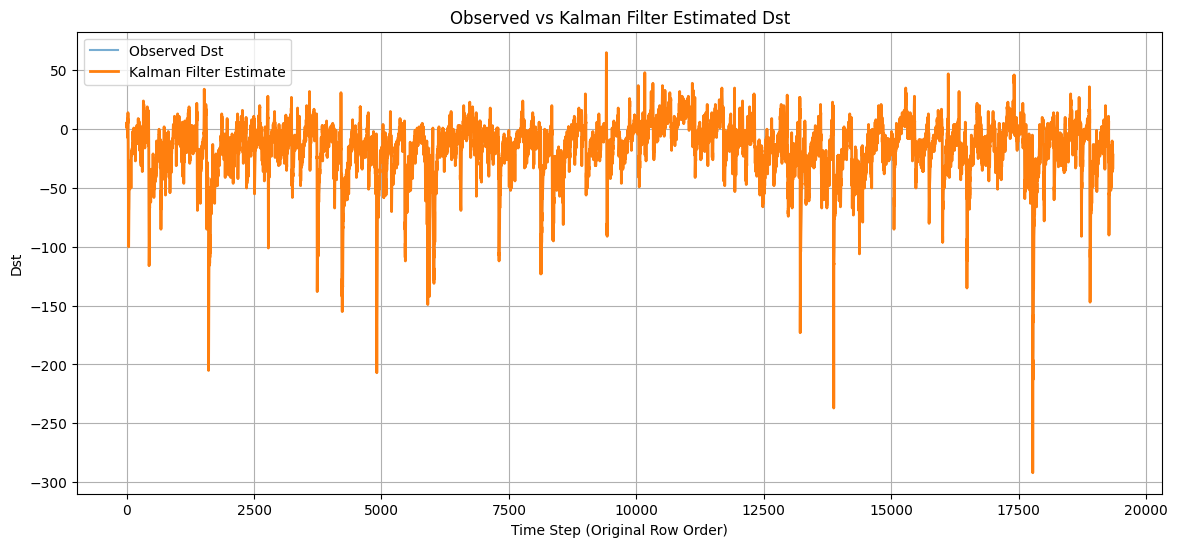

In [ ]:

plt.figure(figsize=(14, 6))

plt.plot(
    dst_series.values,
    label="Observed Dst",
    alpha=0.6
)

plt.plot(
    filtered_dst,
    label="Kalman Filter Estimate",
    linewidth=2
)

plt.xlabel("Time Step (Original Row Order)")
plt.ylabel("Dst")
plt.title("Observed vs Kalman Filter Estimated Dst")
plt.legend()
plt.grid(True)

plt.savefig(
    "/content/results/pratistha/kalman_filter_estimate.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


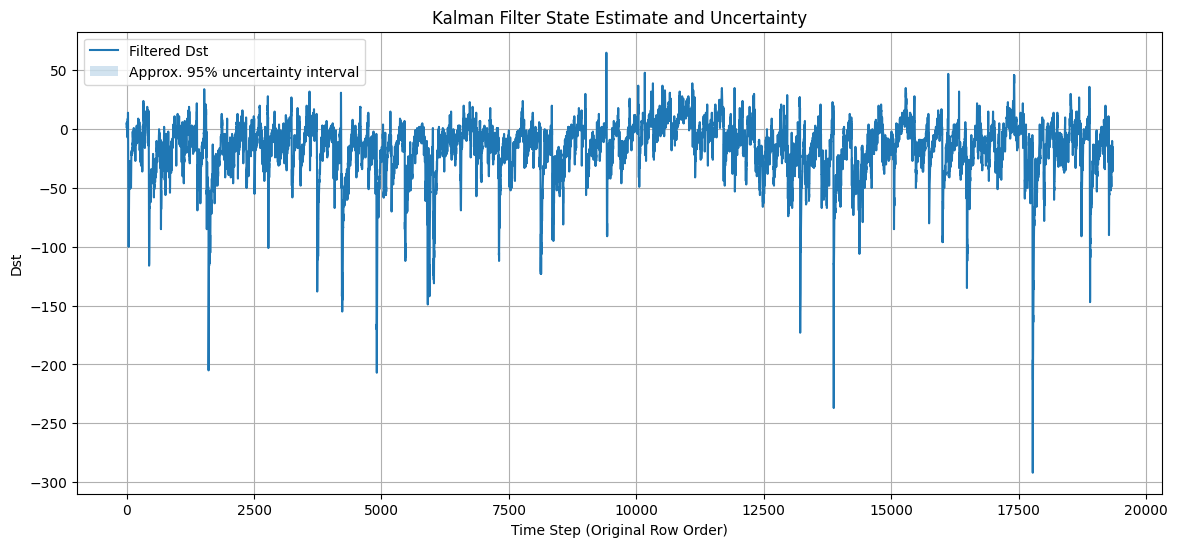

In [ ]:

uncertainty = np.sqrt(np.maximum(filtered_variance, 0))

plt.figure(figsize=(14, 6))

plt.plot(
    filtered_dst,
    label="Filtered Dst"
)

plt.fill_between(
    range(len(filtered_dst)),
    filtered_dst - 1.96 * uncertainty,
    filtered_dst + 1.96 * uncertainty,
    alpha=0.2,
    label="Approx. 95% uncertainty interval"
)

plt.xlabel("Time Step (Original Row Order)")
plt.ylabel("Dst")
plt.title("Kalman Filter State Estimate and Uncertainty")
plt.legend()
plt.grid(True)

plt.savefig(
    "/content/results/pratistha/kalman_uncertainty.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [ ]:
print("Your generated results:")

for root, dirs, files in os.walk("/content/results/pratistha"):
    for file in files:
        print(file)

Your generated results:
factor_loading_heatmap.png
factor_loadings.csv
pca_scree_plot.png
pca_2d_projection.png
kalman_filter_estimate.png
pca_cumulative_variance.png
pca_explained_variance.csv
kalman_uncertainty.png


In [ ]:
import shutil
from google.colab import files

shutil.make_archive(
    "/content/pratistha_results",
    "zip",
    "/content/results/pratistha"
)

files.download("/content/pratistha_results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>